In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ml_library.preprocessing.empty_values_remove import empty_values_remove

# **Projeto Final — Aprendizado de Máquina I (2026.2) · Parte II: aplicação**
### Grupo: *Machine Learning Name in progress*

- Tipo de problema: **Regressão**
- Conjunto de dados: [**SRAG — Sivep-Gripe**](https://dadosabertos.saude.gov.br/dataset/srag-2019-a-2026)
- Objetivo principal: **estimar as notificações semanais de Síndrome Respiratória Aguda Grave (SRAG) com Vírus Sincicial Respiratório (VSR) em bebês menores de 6 meses em um cenário de referência sem a campanha de vacinação materna**


- **Equipe responsável**
    - Ryan Kevin
    - Gabriel Falcão
    - Marcelo Lopes
- **Revisão** 
    - Lucas Vieira
    - Mateus Almeida

## 0. Configuração e reprodutibilidade

- A base com o recorte de "< ou =" 4 está em `data/vsr.csv`.
- A célula de leitura usa pandas. A equipe deverá registrar aqui a versão da biblioteca do grupo e a semente dos modelos que precisarem dela.
- Execute o notebook a partir da raiz do repositório.

## 1. Problema e dados

**Pergunta de regressão:** se a relação observada antes da campanha de vacinação materna contra o VSR se mantivesse, quantas notificações semanais de SRAG com VSR esperaríamos em bebês de **0 a menos de 6 meses** em 2026?

- **Alvo:** contagem de notificações de SRAG com VSR no grupo de 0 a <6 meses.
- **Entradas:** contagens de SRAG com VSR na mesma semana em 6 a <12, 12 a <24 e 24 a <48 meses.
- **Unidade de análise:** uma semana nacional, agrupada pela data dos primeiros sintomas.
- **Referência histórica:** usar dados anteriores à campanha do SUS, iniciada em 04/12/2025. Reservar um período anterior à campanha para o teste. O arquivo reúne os extratos de 2023 a 2026. Usar a data dos primeiros sintomas para separar o histórico anterior à campanha das semanas do cenário em 2026.

O cenário supõe que a relação histórica entre as faixas etárias se manteria. As faixas mais velhas servem como referência para a circulação do vírus. Como algumas crianças menores de 24 meses são elegíveis ao nirsevimabe, testamos a sensibilidade usando apenas 24 a <48 meses. A diferença entre o observado e o estimado depende dessa hipótese e pode refletir outras mudanças, como testagem e notificação. 
[Início da campanha](https://www.gov.br/saude/pt-br/assuntos/noticias/2025/dezembro/gestantes-ja-podem-se-vacinar-contra-a-bronquiolite)
[Nota técnica sobre nirsevimabe](https://www.gov.br/saude/pt-br/centrais-de-conteudo/publicacoes/notas-tecnicas/2026/nota-tecnica-conjunta-no-87-2026-svsa-saps-saes-sesai-ms.pdf/%40%40download/file)

### 1.1 Carregamento dos dados

O arquivo contém as notificações dos extratos de 2023 a 2026 para crianças de **até 4 anos completos**, ou seja, desde o nascimento até antes do quinto aniversário. Todas as colunas e os valores das linhas selecionadas foram preservados. O único filtro aplicado foi o de idade.

Como a idade é registrada: `NU_IDADE_N` é um número e `TP_IDADE` indica a unidade. Por exemplo, idade 4 com unidade 2 significa **4 meses**, enquanto idade 4 com unidade 3 significa **4 anos completos**. A idade é registrada na data dos primeiros sintomas.

| `TP_IDADE` | Unidade | Valores de `NU_IDADE_N` incluídos |
|---|---|---|
| 1 | Dias | 0 a 31 |
| 2 | Meses | 0 a 59 |
| 3 | Anos completos | 0 a 4 |

Registros com idade ausente ou unidade inválida ficam fora do recorte. Uma criança registrada com 4 anos entra na base, mas fica fora da faixa explicativa de **24 a menos de 48 meses**. A equipe usará as faixas de 0 a <6, 6 a <12, 12 a <24 e 24 a <48 meses ao construir o painel.


In [30]:
DATA_PATH = "data/vsr.csv"
df = pd.read_csv(DATA_PATH, sep=";", low_memory=False)
df.shape

(514225, 5)

### 1.2 Campos de referência e origem

| Coluna | Uso no pipeline |
|---|---|
| `DT_SIN_PRI` | Data dos primeiros sintomas. Usar para agrupar as notificações por semana. |
| `TP_IDADE`, `NU_IDADE_N` | Tipo e valor da idade. Usar em conjunto para construir as faixas etárias. |
| `PCR_VSR`, `AN_VSR` | Indicadores de detecção de VSR. Ao montar o alvo e as entradas, considerar positivo quando pelo menos um deles for 1 e contar a notificação uma vez. |

Extratos do Sivep-Gripe usados no CSV: [2023](https://s3.sa-east-1.amazonaws.com/ckan.saude.gov.br/SRAG/2023/INFLUD23-23-03-2026.parquet) e [2024](https://s3.sa-east-1.amazonaws.com/ckan.saude.gov.br/SRAG/2024/INFLUD24-23-03-2026.parquet), de 23/03/2026; [2025](https://s3.sa-east-1.amazonaws.com/ckan.saude.gov.br/SRAG/2025/INFLUD25-02-11-2026.parquet) e [2026](https://dadosabertos.saude.gov.br/dataset/srag-2019-a-2026/resource/74091efc-3f75-42e8-a6fa-6b79a8d30582), de 02/11/2026. As 194 colunas foram alinhadas pelo nome. Os extratos históricos em Parquet foram convertidos para CSV. [Dicionário de dados](https://s3.sa-east-1.amazonaws.com/ckan.saude.gov.br/SRAG/dicionario-de-dados-2019-a-2025.pdf)

> lucas: o csv desta versão tem cinco colunas, não 194. atualizar os textos de 1.1 e 1.2 para distinguir o recorte original do arquivo efetivamente distribuído.

## 2. Análise exploratória (EDA)

### 2.1 Dimensões, tipos e primeiras linhas

Conferir datas, códigos de idade e valores dos indicadores de VSR.

In [31]:
# Primeiras linhas do dataset
print(f"Dataset com {df.shape[0]} linhas e {df.shape[1]} preditores:")
df.head()

Dataset com 514225 linhas e 5 preditores:


,DT_SIN_PRI,NU_IDADE_N,TP_IDADE,PCR_VSR,AN_VSR
0,2023-01-16 00:00:00,7,2,1.0,NaN
1,2023-04-11 00:00:00,3,2,1.0,NaN
2,2023-08-07 00:00:00,3,3,NaN,NaN
3,2023-07-30 00:00:00,1,3,NaN,NaN
4,2023-08-24 00:00:00,19,1,1.0,NaN


Vamos padronizar o formato das datas

In [32]:
# Padronizando como AAAA-MM-DD
df['DT_SIN_PRI'] = pd.to_datetime(df['DT_SIN_PRI'], format='mixed', utc=True)
df['DT_SIN_PRI'] = df['DT_SIN_PRI'].dt.date
df['DT_SIN_PRI'] = pd.to_datetime(df['DT_SIN_PRI'])

In [33]:
# Informações básicas
print("Informações básicas do dataset:")
df.info()

Informações básicas do dataset:
<class 'pandas.DataFrame'>
RangeIndex: 514225 entries, 0 to 514224
Data columns (total 5 columns):
 #   Column      Non-Null Count   Dtype        
---  ------      --------------   -----        
 0   DT_SIN_PRI  514225 non-null  datetime64[s]
 1   NU_IDADE_N  514225 non-null  int64        
 2   TP_IDADE    514225 non-null  int64        
 3   PCR_VSR     119047 non-null  float64      
 4   AN_VSR      33409 non-null   float64      
dtypes: datetime64[s](1), float64(2), int64(2)
memory usage: 19.6 MB


In [34]:
df.head()

,DT_SIN_PRI,NU_IDADE_N,TP_IDADE,PCR_VSR,AN_VSR
0,2023-01-16,7,2,1.0,NaN
1,2023-04-11,3,2,1.0,NaN
2,2023-08-07,3,3,NaN,NaN
3,2023-07-30,1,3,NaN,NaN
4,2023-08-24,19,1,1.0,NaN


### 2.2 Valores ausentes

Verificar datas e indicadores ausentes. Campo de exame vazio não equivale a um teste negativo.

In [35]:
# Qtd. de valores ausentes
print("Quantidade de valores ausentes por coluna:")
print(df.isna().sum())

Quantidade de valores ausentes por coluna:
DT_SIN_PRI         0
NU_IDADE_N         0
TP_IDADE           0
PCR_VSR       395178
AN_VSR        480816
dtype: int64


Linhas com NaN em 'PCR_VSR' e 'AN_VSR' significam crianças que não fizeram o teste ou tiveram resultado negativo.

Vamos selecionar apenas as linhas das crianças que tiveram resultado positivo em pelo menos um dos testes.

In [36]:
# Remove linhas com duplo NaN em 'PCR_VSR' e 'AN_VSR'
df = empty_values_remove(df, ['PCR_VSR', 'AN_VSR'], any_missing=False)
print(f"Número de crianças com pelo menos um positivo: {df.shape[0]}")

Número de crianças com pelo menos um positivo: 143505


> lucas: remover linhas com dois valores ausentes não é, em geral, um filtro de positividade. preferir um filtro explícito que mantenha a notificação quando pelo menos um dos dois indicadores de vsr for igual a 1. neste csv, as duas regras selecionam as mesmas 143.505 linhas, mas isso pode mudar em futuras atualizações. campo vazio não permite concluir que o exame foi negativo.

In [37]:
print("Quantidade de valores ausentes por coluna pós filtração:")
print(df.isna().sum())

Quantidade de valores ausentes por coluna pós filtração:
DT_SIN_PRI         0
NU_IDADE_N         0
TP_IDADE           0
PCR_VSR        24458
AN_VSR        110096
dtype: int64


### 2.3 Distribuição da variável-alvo

Explorar as contagens semanais de 0 a <6 meses no período de desenvolvimento.

In [38]:
# Calcular número de crianças com até seis meses.
df_6_meses = df[(df['TP_IDADE'] == 1) | ((df['TP_IDADE'] == 2) & (df['NU_IDADE_N'] <= 6))]
print(f"Há {df_6_meses.shape[0]} crianças de 0 a seis meses no banco de dados em um total de {df.shape[0]}.")

Há 78540 crianças de 0 a seis meses no banco de dados em um total de 143505.


In [39]:
# Agrupando casos de vsr por semana
contagem_semanal = df.resample('W', on='DT_SIN_PRI').size()

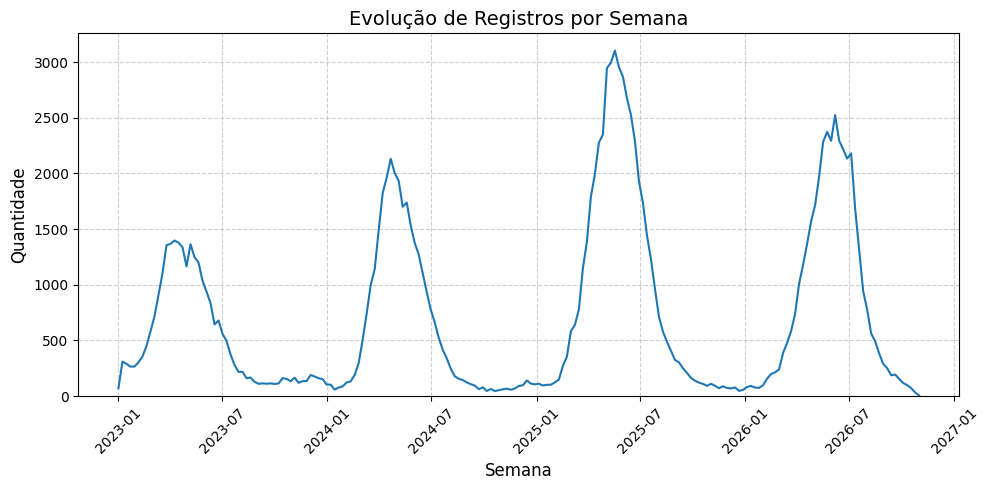

In [40]:
# Plotando gráfico de número de casos semanais de 2023 a 2026
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(contagem_semanal.index, contagem_semanal.values)

ax.set_title('Evolução de Registros por Semana', fontsize=14)
ax.set_xlabel('Semana', fontsize=12)
ax.set_ylabel('Quantidade', fontsize=12)

plt.xticks(rotation=45)

ax.set_ylim(bottom=0)

ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

> lucas: em 2.3, o alvo é de 0 a **menos de** 6 meses; a condição `<= 6` inclui crianças de 6 meses. o gráfico seguinte usa `df` inteiro, não o grupo-alvo. avaliar restringi-lo ao alvo e ao período de desenvolvimento, usando semanas encerradas no sábado, como nas partes 3 e 4. isso também evita usar o teste e o cenário para orientar escolhas de modelos.

A partir desse gráfico podemos observar o comportamento sazonal da doença nos últimos 4 anos.

### 2.4 Relação entre variáveis

Investigar correlação e colinearidade entre as contagens semanais.

In [41]:
# Pondo todas as idades em meses.
condicoes = [
    df['TP_IDADE'] == 1,  # Dias
    df['TP_IDADE'] == 2,  # Meses
    df['TP_IDADE'] == 3,  # Anos
]
escolhas = [df['NU_IDADE_N'] / 30.4375, df['NU_IDADE_N'], df['NU_IDADE_N'] * 12]
df['IDADE_MESES'] = np.select(condicoes, escolhas, default=np.nan)

In [42]:
df.head()

,DT_SIN_PRI,NU_IDADE_N,TP_IDADE,PCR_VSR,AN_VSR,IDADE_MESES
0,2023-01-16,7,2,1.0,NaN,7.000000
1,2023-04-11,3,2,1.0,NaN,3.000000
2,2023-08-24,19,1,1.0,NaN,0.624230
3,2023-06-08,5,2,1.0,NaN,5.000000
4,2023-03-29,20,1,1.0,NaN,0.657084


In [43]:
# Criando classes de faixa etária no dataframe de 0 a 6, 6 a 12, 12 a 24 e 24 a 48 meses de idade.
limites = [0, 6, 12, 24, 48]
rotulos = ['0-6', '6-12', '12-24', '24-48']
df['FAIXA_ETARIA'] = pd.cut(
    df['IDADE_MESES'], bins=limites, labels=rotulos, right=False
)

In [44]:
# Calculando número de casos semanais para cada faixa etária
contagem_semanal = (
    df.groupby([pd.Grouper(key='DT_SIN_PRI', freq='W'), 'FAIXA_ETARIA'], observed=False)
    .size()
    .unstack(fill_value=0)
)

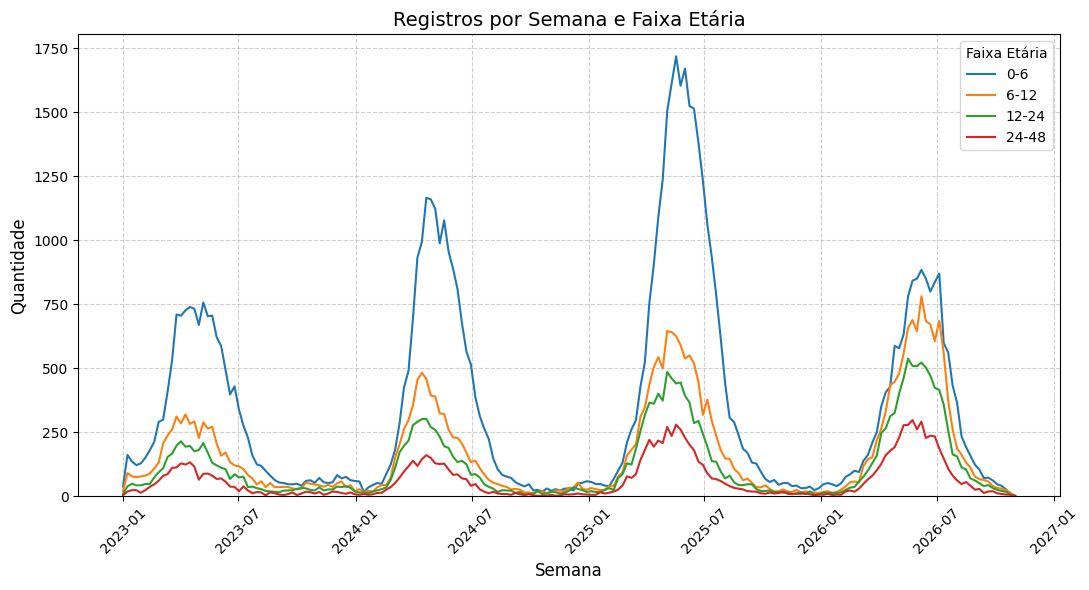

In [45]:
# Plotando número de casos semanais por faixa etária de 2023 a 2026.
fig, ax = plt.subplots(figsize=(11, 6))

for faixa in rotulos:
    ax.plot(
        contagem_semanal.index,
        contagem_semanal[faixa],
        label=faixa,
    )

# 6. Personalizar layout e eixos
ax.set_title('Registros por Semana e Faixa Etária', fontsize=14)
ax.set_xlabel('Semana', fontsize=12)
ax.set_ylabel('Quantidade', fontsize=12)
ax.legend(title='Faixa Etária')

plt.xticks(rotation=45)
ax.set_ylim(bottom=0)

ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [46]:
# Calculando correlação entre faixas etárias
matriz_correlacao = contagem_semanal.corr(method='pearson')

print('Matriz de Correlação Semanal entre Faixas Etárias:')
print(matriz_correlacao.round(2))

Matriz de Correlação Semanal entre Faixas Etárias:
FAIXA_ETARIA   0-6  6-12  12-24  24-48
FAIXA_ETARIA                          
0-6           1.00  0.88   0.84   0.84
6-12          0.88  1.00   0.99   0.97
12-24         0.84  0.99   1.00   0.99
24-48         0.84  0.97   0.99   1.00


In [47]:
# Calculando matriz de correlação com corte em dezembro de 2025
contagem_ate_2026 = contagem_semanal[contagem_semanal.index.year < 2026] # Casos por semana até dezembro de 2025.

matriz_correlacao = contagem_ate_2026.corr(method='pearson')

print('Matriz de correlação semanal até dezembro de 2025:')
print(matriz_correlacao.round(2))

Matriz de correlação semanal até dezembro de 2025:
FAIXA_ETARIA   0-6  6-12  12-24  24-48
FAIXA_ETARIA                          
0-6           1.00  0.96   0.93   0.92
6-12          0.96  1.00   0.99   0.98
12-24         0.93  0.99   1.00   0.99
24-48         0.92  0.98   0.99   1.00


### 2.5 Conclusões da EDA

Concluimos que o número de casos semanais de crianças de 0 a 6 meses possui uma alta correlação com o número de casos semanais de crianças com mais de 6 meses o que viabilisa realizar uma regressão para o número de casos de VSR em crianças de 0 a 6 meses em 2026 com base no número de casos semanais de crianças com mais de 6 meses para avaliar o impacto da vacinação.

> lucas: correlação alta motiva testar os modelos, mas não comprova capacidade de generalização nem efeito causal da vacinação. a correlação de 2.4 ainda inclui semanas de dezembro de 2025; para uma referência pré-campanha, usar o corte de 29/11/2025. a comparação preditiva deve vir da validação temporal, e a estimativa para 2026 depende da estabilidade da relação entre idades.

## 3. Divisão treino/teste

### 3.1 Unidade de observação

Conferir que o painel agregado tem uma linha por semana. Definir um critério para checar duplicidades antes de agregar.

In [48]:
# Semana começa no domingo e vai até o sábado:
FREQ = "W-SAT"

# "TP_IDADE" == 3: o tipo da idade está representada em ANOS
# "NU_IDADE_N" == 0: idade de 0 anos (não dá pra classificar com TP = 3)
ano_zero = (df["TP_IDADE"] == 3) & (df["NU_IDADE_N"] == 0)

# Remove os casos de 'ano 0' pelo índice
df_panel = df.drop(df[ano_zero].index)
print(f"Linhas com 'ano 0' removidas: {len(df) - len(df_panel)}")

# Linhas idênticas: mantidas
#   - Não temos nenhuma identificação sobre as crianças (!!)
#   - Crianças que foram transferidas entre hospitais constam 2 registros diferentes
#   - Crianças diferentes mas com mesmas informações (mais provável em picos!!)
print(f"Linhas idênticas: {df_panel.duplicated().sum()}")

# Contar notificações por semana (semana, faixa)
painel = (
    df_panel.groupby(   # Agrupa por semana + faixa etária
            [pd.Grouper(key="DT_SIN_PRI", freq=FREQ), "FAIXA_ETARIA"],
            observed=False, # Queremos ter uma noção até dos grupos que
                            # não foram observados
    )
    .size() # Número de dados em cada grupo separado
    .unstack(fill_value=0)  # Cria colunas com base nas variáveis categóricas
                            # Neste caso, ["0-6","6-12","12-24","24-48"]
    )  

# Número de semanas antes do ajuste
n_before = len(painel)

# Lista de todos os sábados entre a primeira e a última semana do painel
# Semanas que não estavam no painel (sem registro) são criadas
painel = painel.asfreq(FREQ, fill_value = 0)

Linhas com 'ano 0' removidas: 16
Linhas idênticas: 109312


### 3.2 Divisão

In [49]:
# Datas de corte (sábados = último dia de cada semana)
CAMPAIGN_START = pd.Timestamp("2025-12-04") # início da vacinação materna no SUS
TEST_START = pd.Timestamp("2025-01-04") # 1ª semana de 2025
TEST_END = pd.Timestamp("2025-11-29")   # última semana inteira antes da campanha
SCENARIO_START = pd.Timestamp("2026-01-10") # 1ª semana inteira de 2026

# Separa as semanas de teste: 2025 até antes da campanha
test_df = painel[(painel.index >= TEST_START) & (painel.index <= TEST_END)]

# Separa as semanas de treino: tudo que vem antes da campanha
train_df = painel[painel.index < TEST_START]

# Semanas de 2026 (cenário de referência)
scenario_df = painel[painel.index >= SCENARIO_START]

> lucas: o csv começa em 01/01/2023 e termina em 31/10/2026. a semana encerrada em 06/01/2024 contém a virada do ano e a de 04/01/2025 inclui dias de 2024; os cortes são por semana, não por ano civil estrito. mesmo a última semana completa pode estar subnotificada. definir o atraso de consolidação antes da parte 8.3 e distinguir ausência de notificações de ausência de cobertura. manter a exclusão de idade em anos igual a zero, pois ela não distingue os menores de 6 meses.

## 4. Pré-processamento

### 4.1 Valores ausentes (checagem)

In [50]:
print(f"Datas de sintomas inválidas: {df_panel['DT_SIN_PRI'].isna().sum()}")
print(f"Valores vazio no painel: {painel.isna().sum().sum()}")

print(f"Semanas com 0 casos em cada faixa:\n{((painel == 0).sum())}")

Datas de sintomas inválidas: 0
Valores vazio no painel: 0
Semanas com 0 casos em cada faixa:
FAIXA_ETARIA
0-6      0
6-12     0
12-24    0
24-48    1
dtype: int64


### 4.3 Escala das variáveis numéricas

In [51]:
from ml_library.preprocessing.standardization import standardization

# Coluna TARGET será prevista
# As outras servirão como preditores
TARGET = "0-6"
FEATURES = ["6-12", "12-24", "24-48"]

def fit_preprocess(train, features=FEATURES):
    # Salva os parâmetros de treino (média e desvio) e padroniza
    _, scale_parameters = standardization(train,features)
    
    return {"features":features, "parameters":scale_parameters}

### 4.4 Matrizes finais

Montar as três colunas explicativas e o alvo, sem incorporar dados do futuro.

In [52]:
# Aplica os parâmetros calculador por fit_preprocess anteriormente
def apply_preprocess(data, params):
    
    copy = data.copy()
    
    # Aplica padronização com média e desvio usados no treino
    for col, p in params["parameters"].items():
        if p["std"] > 0:
            copy[col] = (copy[col] - p["mean"]) / p["std"]
        # Segue a convenção de desvio 0 => coluna de 0.0
        else:
            copy[col] = 0.0

    # Colunas explicativas (features)
    X = copy[params["features"]].to_numpy(dtype=float)
        
    # Alvo (em casos por semana)
    Y = copy[TARGET].to_numpy(dtype=float)
        
    return X, Y
    
# Calcula os parâmetros usando treino (média e desvio)
# Devem ser os mesmos usados na padronização do teste
params = fit_preprocess(train_df)    

# Aplica o preprocess nos dados:
#   - Dados de treino
#   - Dados de teste
#   - Dados após início da vacinação
X_train, y_train = apply_preprocess(train_df, params)
X_test, y_test = apply_preprocess(test_df, params)
X_scen, y_scen = apply_preprocess(scenario_df, params)

# Teste de sensibilidade usando a faixa 24-48 como referência
params_24 = fit_preprocess(train_df, ["24-48"])
X_train_24, _ = apply_preprocess(train_df, params_24)
X_test_24, _ = apply_preprocess(test_df, params_24)
X_scen_24, _ = apply_preprocess(scenario_df, params_24)

## 5. Modelos candidatos

Definimos candidatos para explicar a contagem semanal em 0 a <6 meses a partir das faixas de referência. Esta etapa prepara e verifica o treinamento; não seleciona o vencedor e não usa `X_test`, `y_test` nem o cenário de 2026. A comparação de desempenho será feita por blocos temporais nas partes 6 e 7.

Usamos os modelos da biblioteca do grupo, incluindo o regressor neural já integrado à `main`. A semente é fixa para que cada novo ajuste seja reproduzível no mesmo ambiente.

> lucas: a dependência atual aponta para a `main`. fixar a dependência no commit validado da biblioteca e versionar o arquivo de lock do ambiente. isso evita que duas execuções instalem versões diferentes.

In [53]:
from ml_library.models.regression import OrdinaryLeastSquares, Ridge, Lasso
from ml_library.utils._random import set_seed

from ml_library.models.neural_network.mlp import MLPRegressor
from ml_library.models.neural_network.activations import Tanh

SEED = 42
set_seed(SEED)

### 5.1 Baseline

O baseline prevê a mediana do alvo no treino para todas as semanas. A mediana minimiza a soma dos erros absolutos entre previsões constantes, sendo uma referência coerente com MAE (erro absoluto médio) como métrica principal. Ela deve ser recalculada somente com o treino de cada bloco temporal.

Este pequeno estimador usa apenas NumPy: não há ajuste de coeficientes nem dependência de outra biblioteca de aprendizado de máquina.

In [54]:
class BaselineMediana:
    def fit(self, X, y):
        self.mediana_ = float(np.median(y))
        return self

    def predict(self, X):
        return np.full(len(X), self.mediana_, dtype=float)

### 5.2 Modelos de regressão

- **OLS:** relação linear com intercepto, sem regularização; referência interpretável para as três contagens.
- **Ridge:** penalização L2, útil como candidata quando as contagens das faixas se correlacionam.
- **Lasso:** penalização L1, que pode zerar coeficientes. Um coeficiente zerado não demonstra ausência de relação causal.

Começamos com `lam=1.0` em Ridge e Lasso, apenas como configuração inicial, não como valor escolhido por desempenho. A biblioteca recebe `lam` em `fit`, não no construtor, e normaliza internamente as variáveis desses dois modelos. O significado numérico da penalização depende da função objetivo implementada; a parte 6 deverá avaliar uma grade por modelo.

O Lasso usa `eps=1e-4` e `max_iter=10000` como controles numéricos iniciais. OLS exige matriz de desenho com posto completo; blocos muito curtos ou colunas constantes podem impedir o ajuste.

### 5.3 Rede neural

Usamos `MLPRegressor` com: 

uma camada oculta de 8 neurônios,

ativação Tanh,

saída linear,

taxa de aprendizado 0,01 e 500 épocas.


São pontos de partida modestos para uma série com poucas semanas de treino, a serem avaliados na parte 6. A implementação usa MSE e gradiente descendente com o conjunto de treino inteiro em cada época; não há early stopping automático.

Além da escala das entradas feita na parte 4, padronizamos o **alvo apenas para a rede neural**, usando média e desvio do treino recebido. Na predição, a transformação é invertida, retornando notificações por semana. Isso evita treinar diretamente com gradientes na escala das contagens, sem usar informações da validação ou do teste.

As saídas de regressão podem ser negativas. Nesta etapa não arredondamos nem truncamos previsões. Caso a equipe adote truncamento em zero, deverá defini-lo antes da seleção e aplicá-lo de forma consistente na validação e no teste.

In [55]:
# cada chamada cria um estimador novo, evitando reaproveitar ajustes entre blocos
CANDIDATOS = {
    "Mediana": {
        "criar": BaselineMediana,
        "construtor": {},
        "ajuste": {},
        "padronizar_alvo": False,
    },
    "OLS": {
        "criar": OrdinaryLeastSquares,
        "construtor": {},
        "ajuste": {"intercept": True},
        "padronizar_alvo": False,
    },
    "Ridge": {
        "criar": Ridge,
        "construtor": {},
        "ajuste": {"lam": 1.0, "intercept": True},
        "padronizar_alvo": False,
    },
    "Lasso": {
        "criar": Lasso,
        "construtor": {},
        "ajuste": {"lam": 1.0, "intercept": True,
                   "eps": 1e-4, "max_iter": 10000},
        "padronizar_alvo": False,
    },
    "MLP": {
        "criar": MLPRegressor,
        "construtor": {"hidden_units": 8, "learning_rate": 0.01,
                       "epochs": 500, "activation": Tanh},
        "ajuste": {},
        "padronizar_alvo": True,
    },
}


def treinar_candidato(nome, X, y, parametros_construtor=None,
                      parametros_ajuste=None, seed=SEED):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    if X.ndim != 2 or y.ndim != 1 or len(X) != len(y) or len(y) == 0:
        raise ValueError("Esperados X bidimensional e y unidimensional não vazios.")
    if not np.isfinite(X).all() or not np.isfinite(y).all():
        raise ValueError("Os dados de treino devem conter apenas valores finitos.")

    config = CANDIDATOS[nome]
    construtor = {**config["construtor"], **(parametros_construtor or {})}
    ajuste = {**config["ajuste"], **(parametros_ajuste or {})}
    media_y, escala_y = 0.0, 1.0
    if config["padronizar_alvo"]:
        media_y = float(y.mean())
        escala_y = float(y.std())
        if escala_y == 0:
            escala_y = 1.0

    set_seed(seed)
    modelo = config["criar"](**construtor)
    # o fit das regressões lineares retorna None; preservamos o objeto original
    modelo.fit(X, (y - media_y) / escala_y, **ajuste)
    return {"modelo": modelo, "media_y": media_y, "escala_y": escala_y}


def prever_candidato(ajustado, X):
    previsao = np.asarray(ajustado["modelo"].predict(X), dtype=float).reshape(-1)
    return previsao * ajustado["escala_y"] + ajustado["media_y"]

### 5.4 Verificação dos candidatos e ligação com a validação

A tabela abaixo verifica somente se cada candidato treina e produz uma previsão finita por semana, tanto com as três faixas como na análise de sensibilidade usando apenas 24 a <48 meses. **Não é uma comparação de desempenho e não calcula erros no teste!!!!!**

Na parte 6, para cada bloco temporal, executar `fit_preprocess` no treino do bloco, aplicar seus parâmetros ao treino e à validação, e chamar `treinar_candidato` com um estimador novo. Não reutilizar as matrizes padronizadas com todo `train_df` nos blocos internos. As funções aceitam configurações alternativas via `parametros_construtor` (MLP) e `parametros_ajuste` (Ridge/Lasso). A padronização do alvo já é recalculada a cada ajuste.

In [56]:
verificacao = []
for referencia, X in {"Três faixas": X_train, "Somente 24 a <48 meses": X_train_24}.items():
    for nome in CANDIDATOS:
        ajustado = treinar_candidato(nome, X, y_train)
        previsao = prever_candidato(ajustado, X)
        assert previsao.shape == y_train.shape, f"Formato inesperado: {nome}"
        assert np.isfinite(previsao).all(), f"Previsões não finitas: {nome}"
        verificacao.append({
            "Referência": referencia,
            "Candidato": nome,
            "Semanas de treino": len(y_train),
            "Preditores": X.shape[1],
            "Verificação": "OK",
        })

pd.DataFrame(verificacao)

,Referência,Candidato,Semanas de treino,Preditores,Verificação
0,Três faixas,Mediana,104,3,OK
1,Três faixas,OLS,104,3,OK
2,Três faixas,Ridge,104,3,OK
3,Três faixas,Lasso,104,3,OK
4,Três faixas,MLP,104,3,OK
5,Somente 24 a <48 meses,Mediana,104,1,OK
6,Somente 24 a <48 meses,OLS,104,1,OK
7,Somente 24 a <48 meses,Ridge,104,1,OK
8,Somente 24 a <48 meses,Lasso,104,1,OK
9,Somente 24 a <48 meses,MLP,104,1,OK


## 6. Validação e seleção de hiperparâmetros

### 6.1 Função de validação

Usar blocos temporais. Em cada bloco, treinar apenas com as semanas anteriores.

### 6.2 Busca de hiperparâmetros

Definir a grade e uma métrica principal, como MAE em notificações por semana.

## 7. Comparação de modelos

### 7.1 Escolha do modelo final

Comparar as métricas da validação e justificar a escolha antes de consultar o teste.

## 8. Avaliação final no conjunto de teste

### 8.1 Treino final

Ajustar o modelo escolhido nas semanas de desenvolvimento.

### 8.2 Métricas e gráficos

Medir o erro no teste pré-campanha e comparar observado e previsto ao longo do tempo.

### 8.3 Cenário de referência para 2026

Após o teste, ajustar com o histórico pré-campanha e estimar as semanas de 2026 a partir das faixas de referência. Justificar o recorte das semanas recentes.

## 9. Conclusão

### 9.1 Interpretação

Resumir o desempenho e discutir a hipótese de estabilidade, o atraso de notificação e o alcance da comparação.